In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklift.datasets import fetch_hillstrom
from scipy.stats import ttest_ind, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
import numpy as np

# Подготовка данных

In [6]:
bunch = fetch_hillstrom(target_col='conversion')
dataset = bunch['data']
target = bunch['target']
treatment = bunch['treatment']
dataset['target'] = target
dataset['treatment'] = treatment 
dataset.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,target,treatment
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,0,Womens E-Mail
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,0,No E-Mail
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,0,Womens E-Mail
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,0,Mens E-Mail
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,0,Womens E-Mail


**Описание столбцов**:
1) recency - Количество месяцев с момента последней покупки.
2) history_segment - Категория суммы, потраченной за последний год.
3) history - Фактическая сумма в долларах, потраченная за последний год.
4) mens	- клиент покупал мужские товары за последний год.
5) womens - клиент покупал женские товары за последний год.
6) zip_code	- Классификация почтового индекса: Urban (город), Suburban (пригород) или Rural (сельская местность).
7) newbie - новый клиент за последние двенадцать месяцев.
8) channel - Канал, через который клиент совершал покупки за последний год.
9) target - Конверсия в покупку в течение 2 недель после коммуникации
10) treatment - воздейстаие на пользователя: Womens E-Mail (рассылка с женскими товарами), Mens E-Mail (рассылка с мужскими товарами), No E-Mail (отсутсвие рассылки, то есть КГ)

# EDA

## Базовый просмотр (пропуски, дубликаты)

In [7]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  str    
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  str    
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  str    
 8   target           64000 non-null  int64  
 9   treatment        64000 non-null  str    
dtypes: float64(1), int64(5), str(4)
memory usage: 4.9 MB


In [8]:
dataset.describe()

,recency,history,mens,womens,newbie,target
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250,0.009031
std,3.507592,256.158608,0.497393,0.497526,0.499999,0.094604
min,1.000000,29.990000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000,0.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000,0.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000,1.000000


In [9]:
dataset.duplicated().sum()

np.int64(7079)

На первичном просмотре можно заметить, что целевое действие совершают довольно редко: как минимум 75% объектов его не совершали. Также мы не можем утверждать, что 7079 действительно являются дубликатами, так как в данных нет идентификатора пользователя, а строки с одинаковыми фичами могут относиться к разным пользователям => удалять некорректно

## Анализ эффектов и сбалансировасти

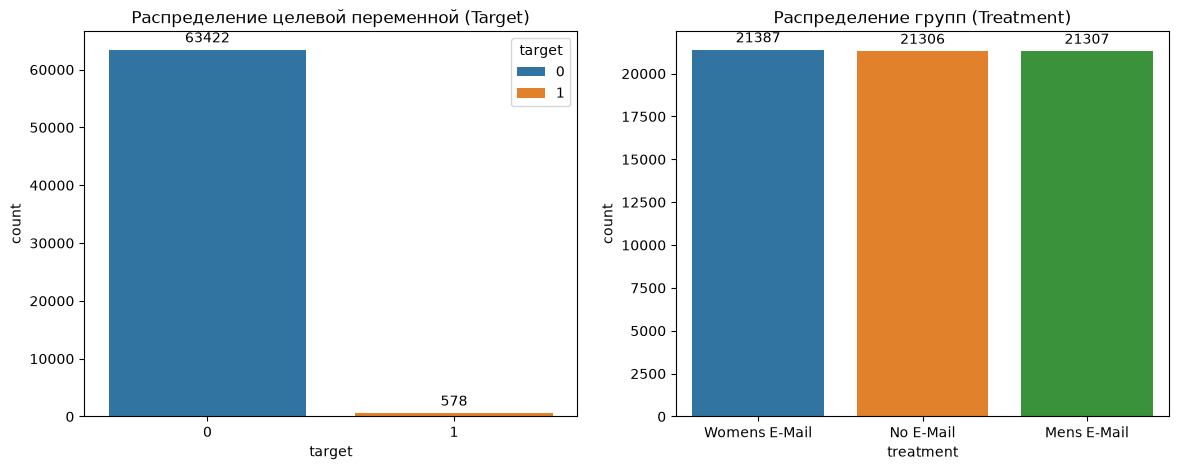

Доля конверсии (target=1): 0.903%
Доли treatment


treatment
Womens E-Mail    0.334172
Mens E-Mail      0.332922
No E-Mail        0.332906
Name: proportion, dtype: float64

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x='target', data=dataset, ax=ax[0], hue='target')
ax[0].set_title('Распределение целевой переменной (Target)')

for container in ax[0].containers:
    ax[0].bar_label(container, padding=3)

sns.countplot(x='treatment', data=dataset, ax=ax[1],  hue='treatment')
ax[1].set_title('Распределение групп (Treatment)')

for container in ax[1].containers:
    ax[1].bar_label(container, padding=3)

plt.show()

print(f"Доля конверсии (target=1): {dataset['target'].mean():.3%}")

print('Доли treatment')
display(dataset['treatment'].value_counts(normalize=True))


In [11]:
def build_uplift_ztest_table(df, target_col, control_name='No E-Mail'):

    # 1. Считаем метрики на контроле
    control_df = df[df['treatment'] == control_name]
    n_control = len(control_df)
    conv_control = control_df[target_col].mean()
    success_control = control_df[target_col].sum()
    
    # 2. Находим все тестовые группы
    test_groups = [t for t in df['treatment'].unique() if t != control_name]
    
    results = []
    
    # 3. Считаем Z-тест для каждой тестовой группы против контроля
    for test_name in test_groups:
        test_df = df[df['treatment'] == test_name]
        n_test = len(test_df)
        conv_test = test_df[target_col].mean()
        success_test = test_df[target_col].sum()
        
        # Z-тест (сравниваем count и nobs)
        count = np.array([success_test, success_control])
        nobs = np.array([n_test, n_control])
        stat, pval = proportions_ztest(count, nobs)
        
        results.append({
            'Compare': f"{test_name} vs {control_name}",
            'N_test': n_test,
            'N_control': n_control,
            'Conv_test': conv_test*100,
            'Conv_control': conv_control*100,
            'absolute effect': (conv_test - conv_control)*100,
            'z_stat': stat,
            'p_value_raw': pval
        })
    
    res_df = pd.DataFrame(results)
    
    # 4. Применяем поправку на множественное тестирование
    reject, pvals_corrected, _, _ = multipletests(res_df['p_value_raw'], alpha=0.05, method='holm')
    
    res_df['p_value_holm'] = pvals_corrected
    res_df['is_significant'] = reject
    
    res_df['Conv_test'] = res_df['Conv_test'].round(2).astype(str) + '%'
    res_df['Conv_control'] = res_df['Conv_control'].round(2).astype(str) + '%'
    res_df['absolute effect'] = res_df['absolute effect'].round(2).astype(str) + '%'
    res_df['z_stat'] = res_df['z_stat'].round(3)
    res_df['p_value_raw'] = res_df['p_value_raw'].apply(lambda x: f"{x:.2e}")
    res_df['p_value_holm'] = res_df['p_value_holm'].apply(lambda x: f"{x:.2e}")
    
    return res_df


table_conversion = build_uplift_ztest_table(dataset, target_col='target')
display(table_conversion)

,Compare,N_test,N_control,Conv_test,Conv_control,absolute effect,z_stat,p_value_raw,p_value_holm,is_significant
0,Womens E-Mail vs No E-Mail,21387,21306,0.88%,0.57%,0.31%,3.780,1.57e-04,1.57e-04,True
1,Mens E-Mail vs No E-Mail,21307,21306,1.25%,0.57%,0.68%,7.385,1.52e-13,3.05e-13,True


###  Баланс числовых фичей

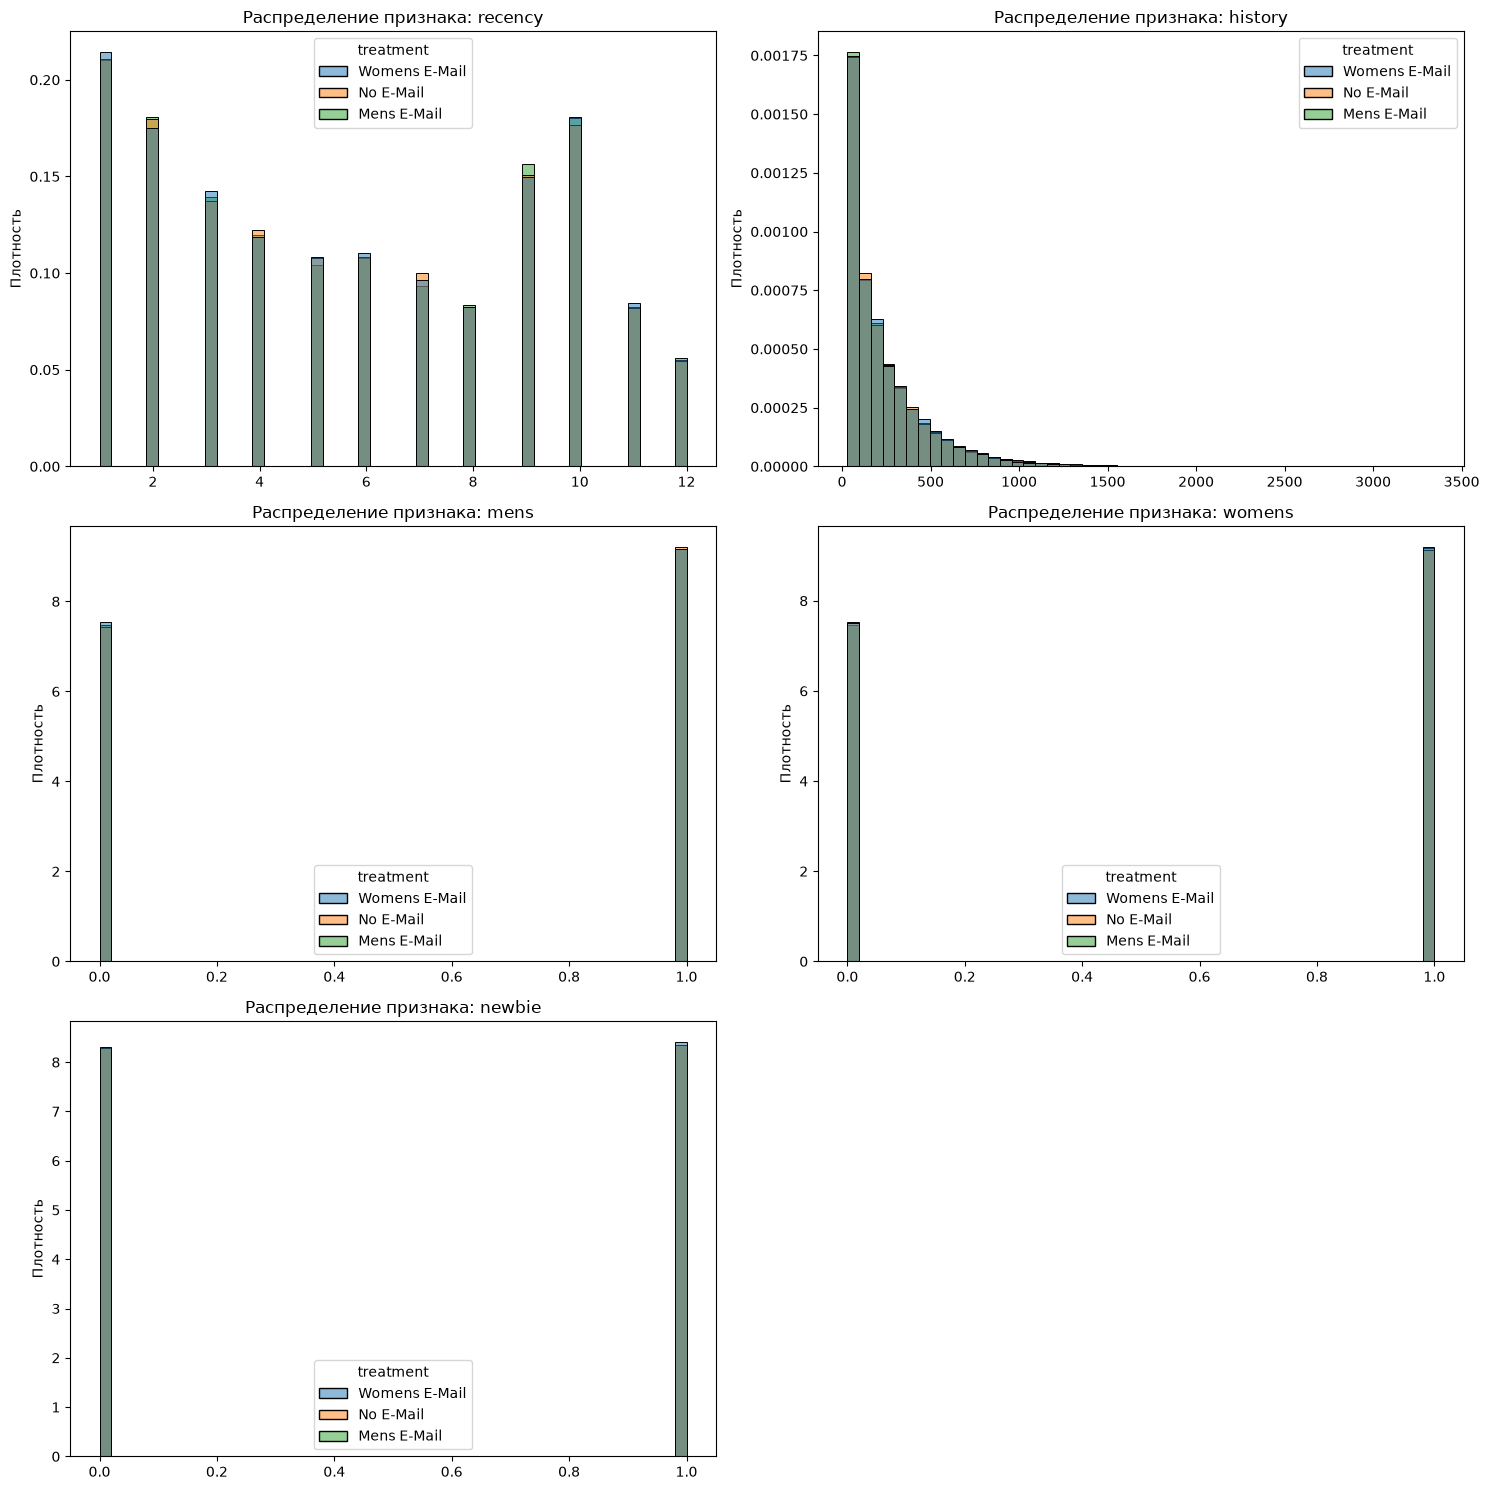

,Feature,Compare,Mean_Test,Mean_Control,SMD,T_Stat,P_Value,Is_Significant
6,history,Mens E-Mail vs No E-Mail,242.836,240.883,0.0076,0.786,4.32e-01,False
7,mens,Mens E-Mail vs No E-Mail,0.551,0.553,0.0046,-0.473,6.36e-01,False
9,newbie,Mens E-Mail vs No E-Mail,0.502,0.502,0.0009,-0.092,9.27e-01,False
5,recency,Mens E-Mail vs No E-Mail,5.774,5.750,0.0068,0.705,4.81e-01,False
8,womens,Mens E-Mail vs No E-Mail,0.551,0.548,0.0076,0.783,4.33e-01,False
1,history,Womens E-Mail vs No E-Mail,242.537,240.883,0.0065,0.673,5.01e-01,False
2,mens,Womens E-Mail vs No E-Mail,0.549,0.553,0.0086,-0.892,3.73e-01,False
4,newbie,Womens E-Mail vs No E-Mail,0.503,0.502,0.0026,0.264,7.92e-01,False
0,recency,Womens E-Mail vs No E-Mail,5.768,5.750,0.0052,0.535,5.93e-01,False
3,womens,Womens E-Mail vs No E-Mail,0.550,0.548,0.0049,0.511,6.09e-01,False


In [ ]:
def analyze_numeric_balance(df, treatment_col, numeric_cols, control_name='No E-Mail'):

    # 1. Построение гистограмм
    n_cols = len(numeric_cols)
    n_rows = (n_cols + 1) // 2  # Сетка 2 колонки
    
    fig, axes = plt.subplots(n_rows, 2, figsize=(15, 5 * n_rows))
    axes = axes.flatten()
    
    for i, col in enumerate(numeric_cols):
        ax = axes[i]
        
        sns.histplot(
            data=df, 
            x=col, 
            hue=treatment_col,
            alpha=0.5,      
            ax=ax,
            stat='density',    
            bins=50
        )
        
        ax.set_title(f'Распределение признака: {col}', fontsize=12)
        ax.set_ylabel('Плотность')
        ax.set_xlabel('')
        
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.tight_layout()
    plt.show()


    # 2. Расчет критериев сбалансированности
    results = []
    control_df = df[df[treatment_col] == control_name]
    test_groups = [t for t in df[treatment_col].unique() if t != control_name]
    
    for group in test_groups:
        test_df = df[df[treatment_col] == group]
        
        for col in numeric_cols:
            x_test = test_df[col].dropna()
            x_control = control_df[col].dropna()
            
            mean_t = x_test.mean()
            mean_c = x_control.mean()
            var_t = x_test.var(ddof=1)
            var_c = x_control.var(ddof=1)
            
            smd = (mean_t - mean_c) / np.sqrt((var_t + var_c) / 2)
            t_stat, p_val = ttest_ind(x_test, x_control, equal_var=False)
            
            results.append({
                'Feature': col,
                'Compare': f"{group} vs {control_name}",
                'Mean_Test': mean_t,
                'Mean_Control': mean_c,
                'SMD': abs(smd),
                'T_Stat': t_stat,
                'P_Value': p_val,
                'Is_Significant': p_val < 0.05
            })
            
    balance_df = pd.DataFrame(results)
    
    # Форматирование таблицы
    balance_df['Mean_Test'] = balance_df['Mean_Test'].round(3)
    balance_df['Mean_Control'] = balance_df['Mean_Control'].round(3)
    balance_df['SMD'] = balance_df['SMD'].round(4)
    balance_df['T_Stat'] = balance_df['T_Stat'].round(3)
    balance_df['P_Value'] = balance_df['P_Value'].apply(lambda x: f"{x:.2e}")
    
    return balance_df.sort_values(by=['Compare', 'Feature'])

# --- ПРИМЕР ИСПОЛЬЗОВАНИЯ ---
numeric_features = ['recency', 'history', 'mens', 'womens', 'newbie']
balance_table = analyze_numeric_balance(dataset, treatment_col='treatment', numeric_cols=numeric_features)
display(balance_table)

### Баланс категориальных фичей

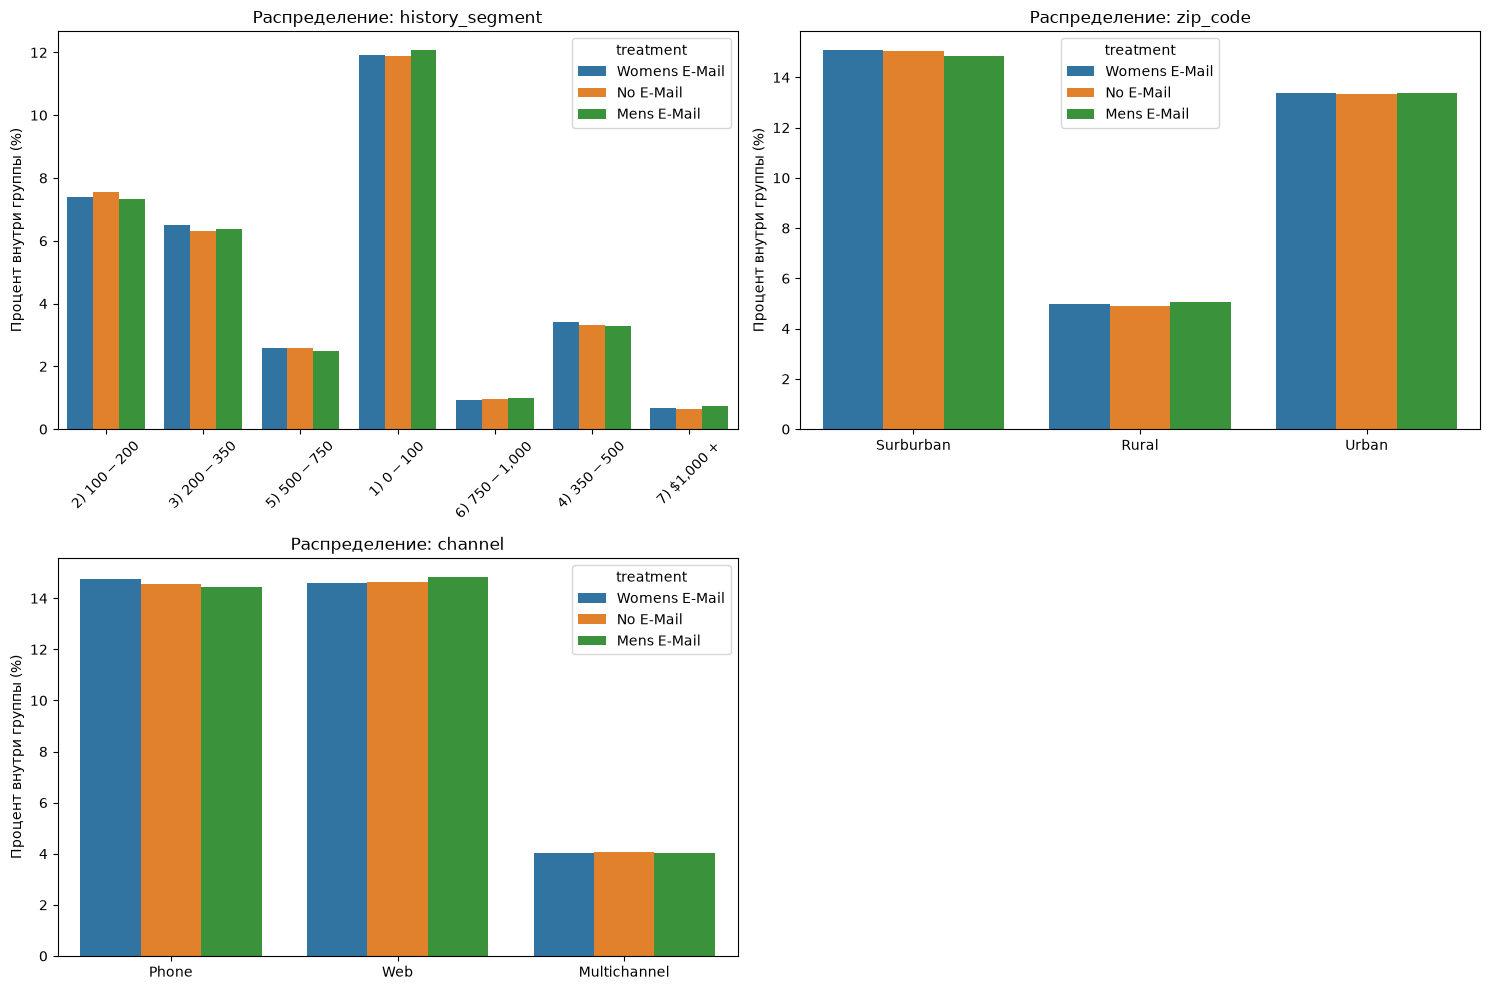

,Feature,Compare,Chi2_Stat,P_Value,Cramers_V,Is_Significant
0,history_segment,Womens E-Mail vs No E-Mail,4.466,6.14e-01,0.0102,False
1,zip_code,Womens E-Mail vs No E-Mail,0.169,9.19e-01,0.0020,False
2,channel,Womens E-Mail vs No E-Mail,0.865,6.49e-01,0.0045,False
3,history_segment,Mens E-Mail vs No E-Mail,7.389,2.86e-01,0.0132,False
4,zip_code,Mens E-Mail vs No E-Mail,2.524,2.83e-01,0.0077,False
5,channel,Mens E-Mail vs No E-Mail,1.296,5.23e-01,0.0055,False


In [ ]:
def analyze_categorical_balance(df, treatment_col, categorical_cols, control_name='No E-Mail'):

    # 1. Построение столбчатых диаграмм
    n_cols = len(categorical_cols)
    n_rows = (n_cols + 1) // 2
    
    fig, axes = plt.subplots(n_rows, 2, figsize=(15, 5 * n_rows))
    axes = axes.flatten()
    
    for i, col in enumerate(categorical_cols):
        ax = axes[i]
        
        sns.countplot(
            data=df, 
            x=col, 
            hue=treatment_col, 
            stat='percent',
            ax=ax,
        )
        
        ax.set_title(f'Распределение: {col}', fontsize=12)
        ax.set_ylabel('Процент внутри группы (%)')
        ax.set_xlabel('')
        
        # Если категорий много, поворачиваем подписи
        if df[col].nunique() > 4:
            ax.tick_params(axis='x', rotation=45)
            
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.tight_layout()
    plt.show()

    # 2. Расчет критериев сбалансированности
    results = []
    control_df = df[df[treatment_col] == control_name]
    test_groups = [t for t in df[treatment_col].unique() if t != control_name]
    
    for group in test_groups:
        subset_df = df[df[treatment_col].isin([group, control_name])]
        
        for col in categorical_cols:
            contingency_table = pd.crosstab(subset_df[col], subset_df[treatment_col])
            
            chi2, p_val, _, _ = chi2_contingency(contingency_table)
            
            n = contingency_table.sum().sum()
            min_dim = min(contingency_table.shape) - 1
            cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0
            
            results.append({
                'Feature': col,
                'Compare': f"{group} vs {control_name}",
                'Chi2_Stat': chi2,
                'P_Value': p_val,
                'Cramers_V': abs(cramers_v),
                'Is_Significant': p_val < 0.05
            })
            
    balance_df = pd.DataFrame(results)
    balance_df['Chi2_Stat'] = balance_df['Chi2_Stat'].round(3)
    balance_df['P_Value'] = balance_df['P_Value'].apply(lambda x: f"{x:.2e}")
    balance_df['Cramers_V'] = balance_df['Cramers_V'].round(4)
    return balance_df

categorical_features = ['history_segment', 'zip_code', 'channel']
cat_balance_table = analyze_categorical_balance(dataset, treatment_col='treatment', categorical_cols=categorical_features)
display(cat_balance_table)

## Анализ влияния фичей на таргет

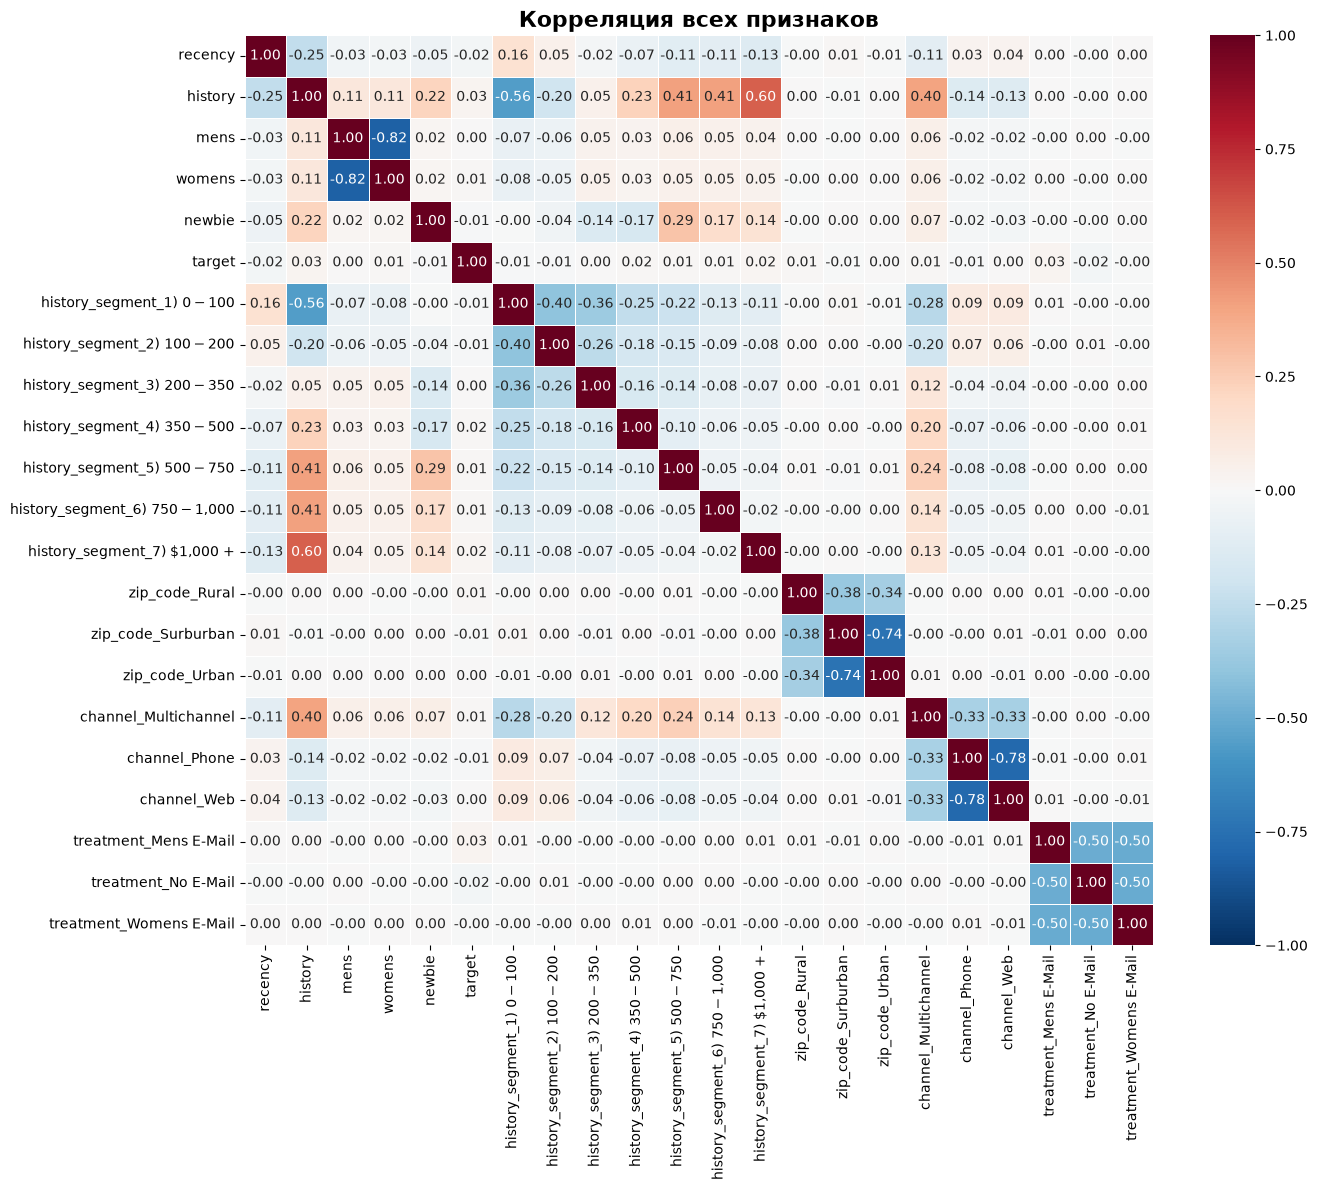

In [14]:
features_df = dataset.copy()

df_encoded = pd.get_dummies(features_df, drop_first=False, dtype=int)

corr = df_encoded.corr()

plt.figure(figsize=(14, 12))

sns.heatmap(
    corr, 
    annot=True, 
    fmt='.2f', 
    cmap='RdBu_r', 
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
)
plt.title('Корреляция всех признаков', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

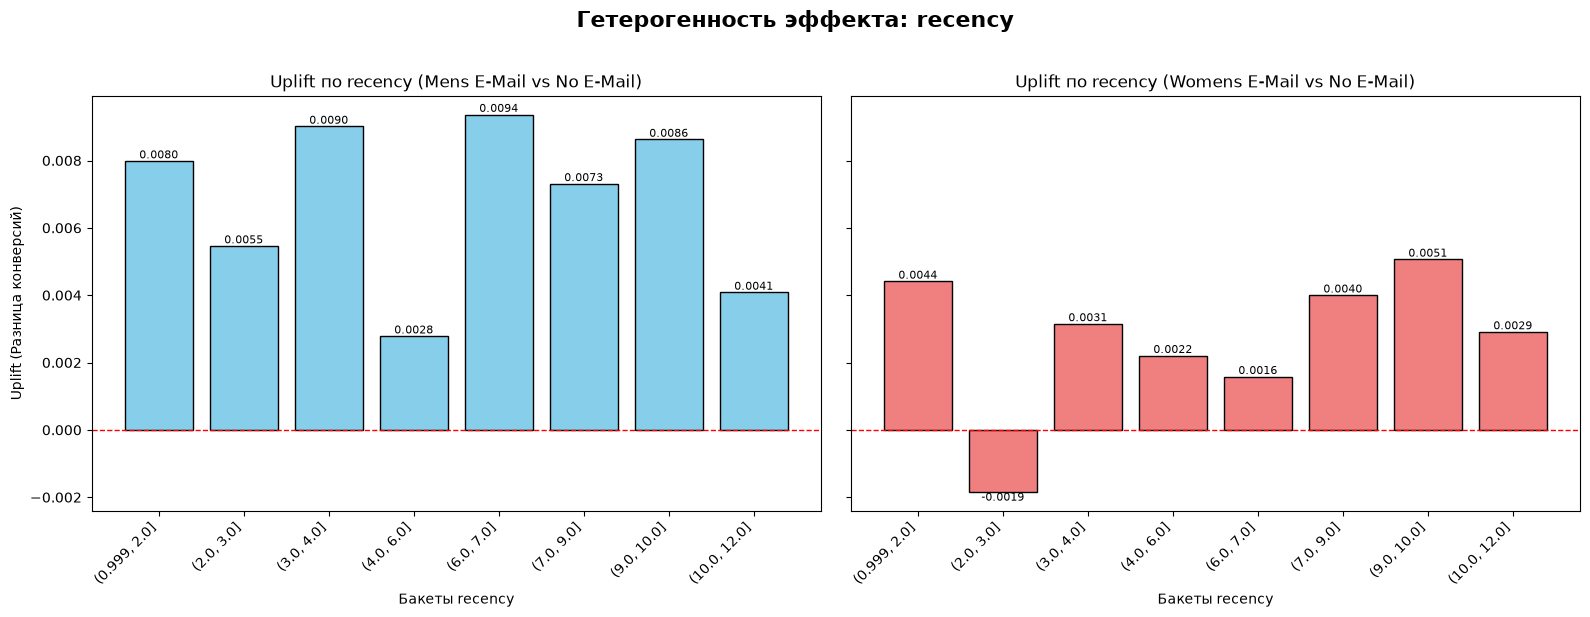

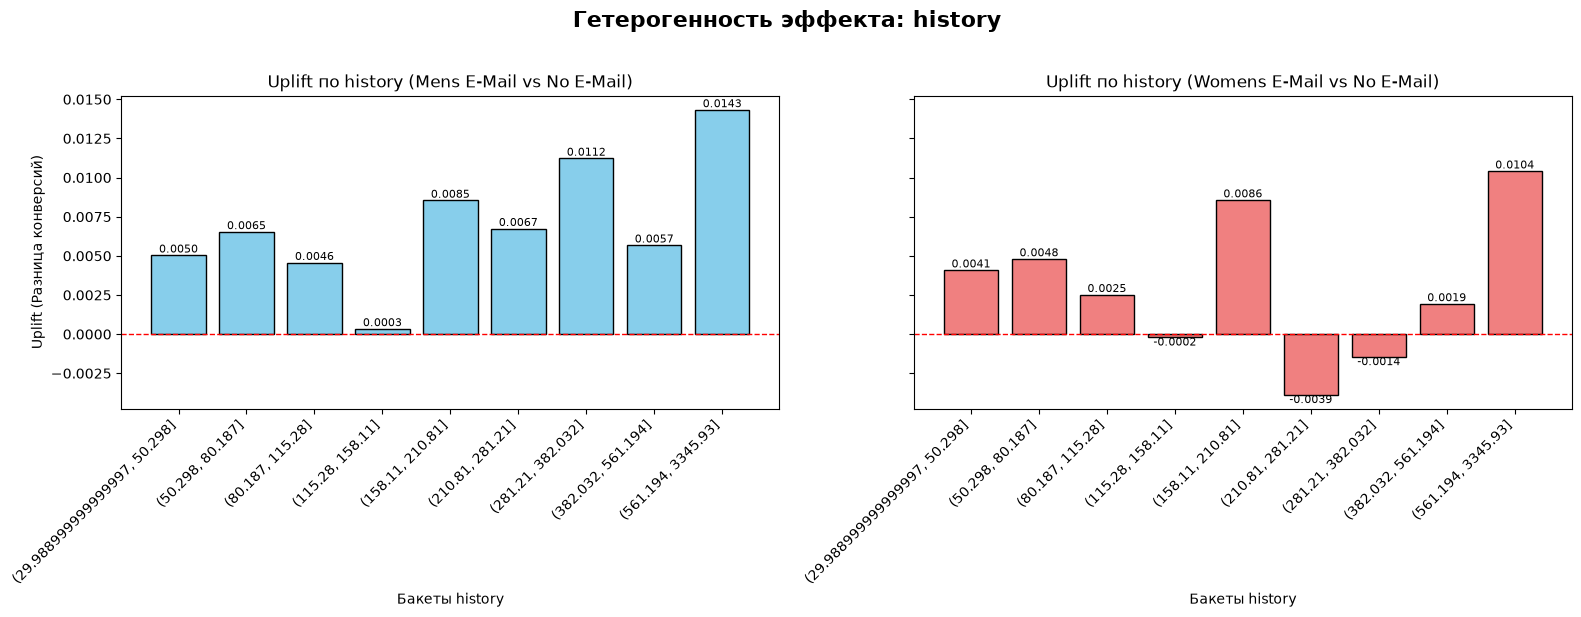

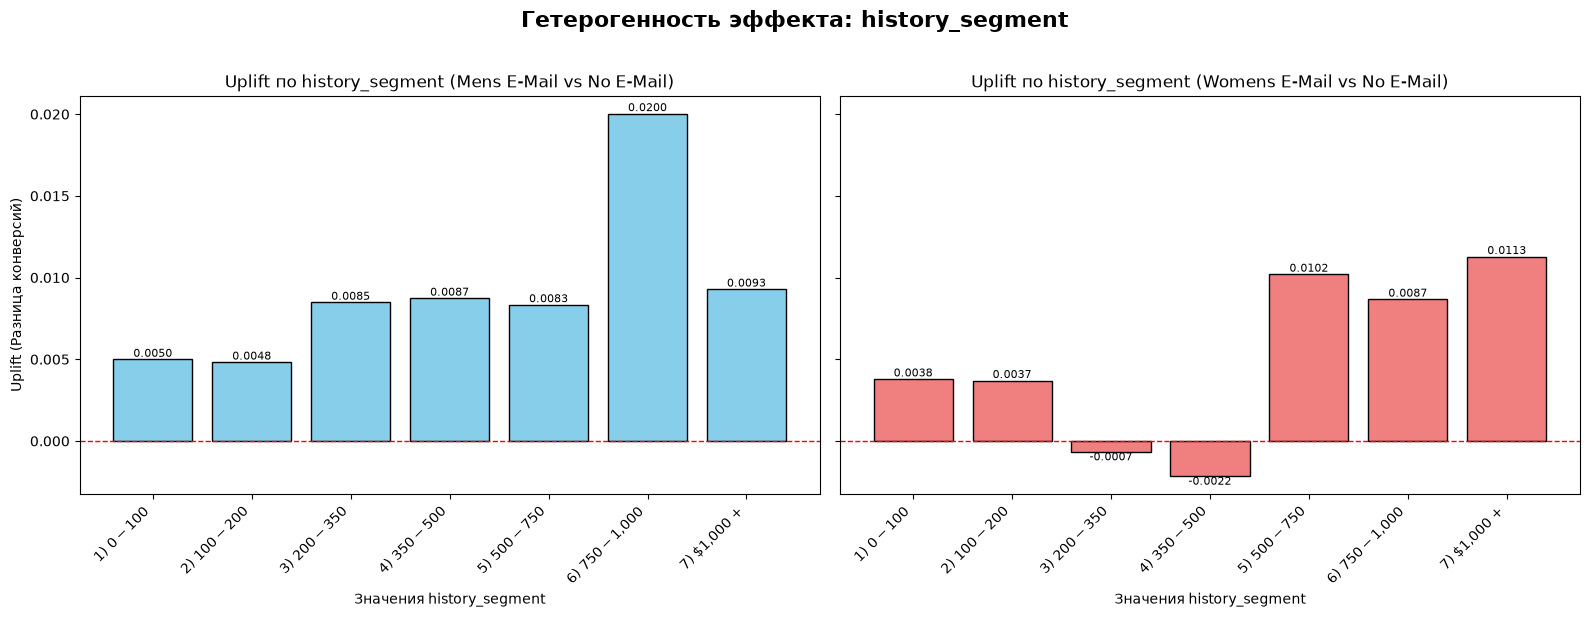

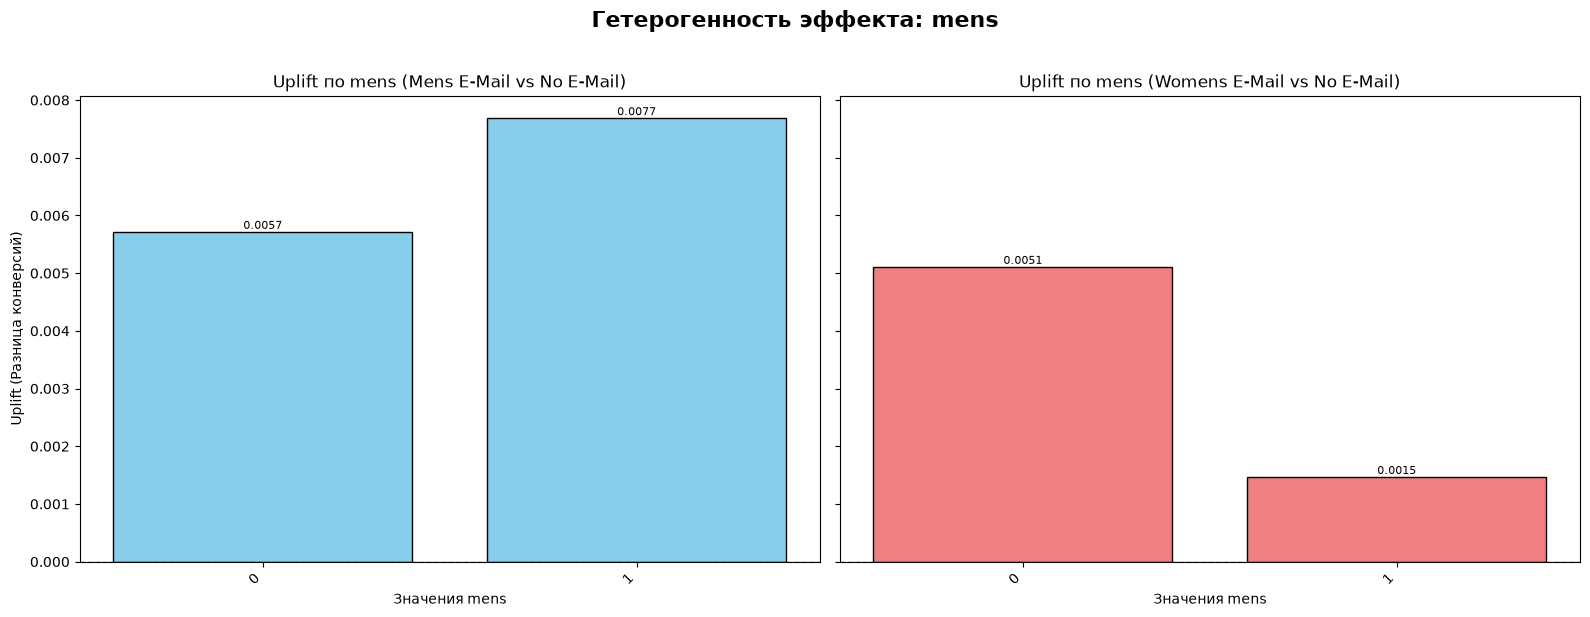

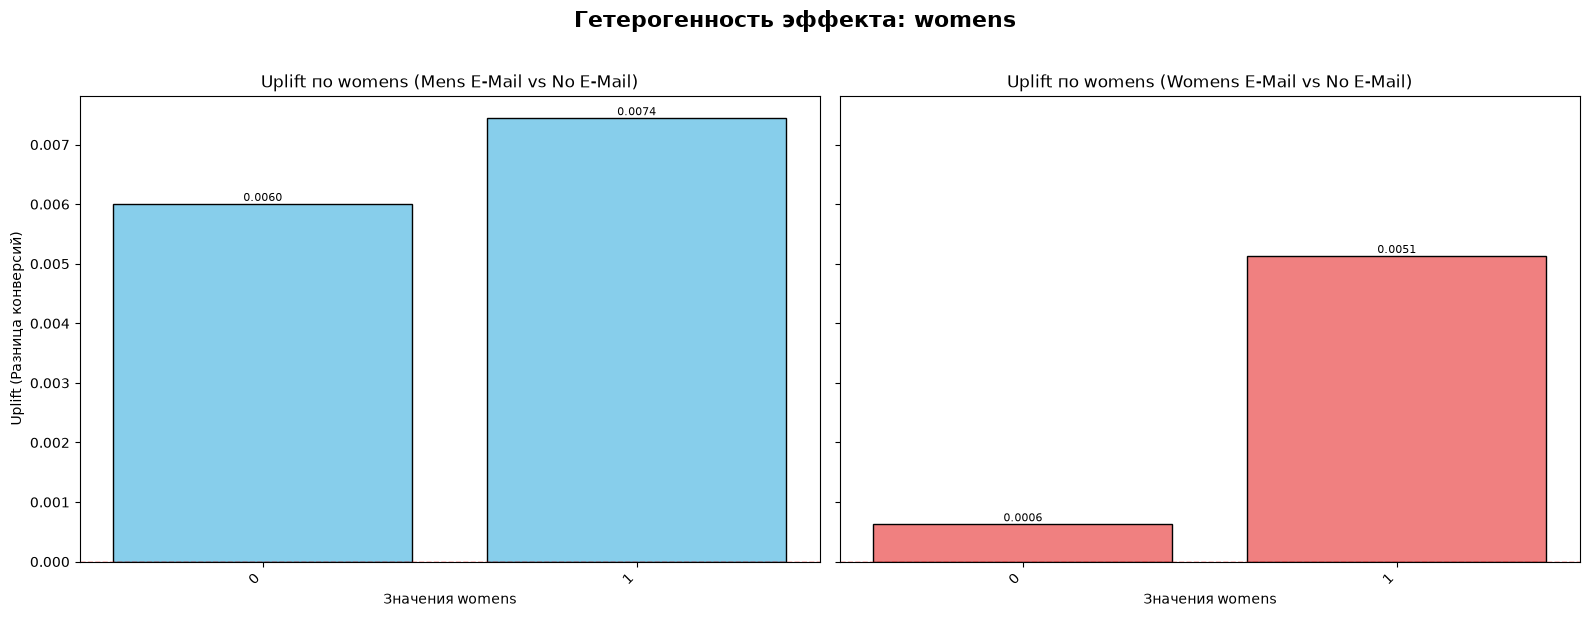

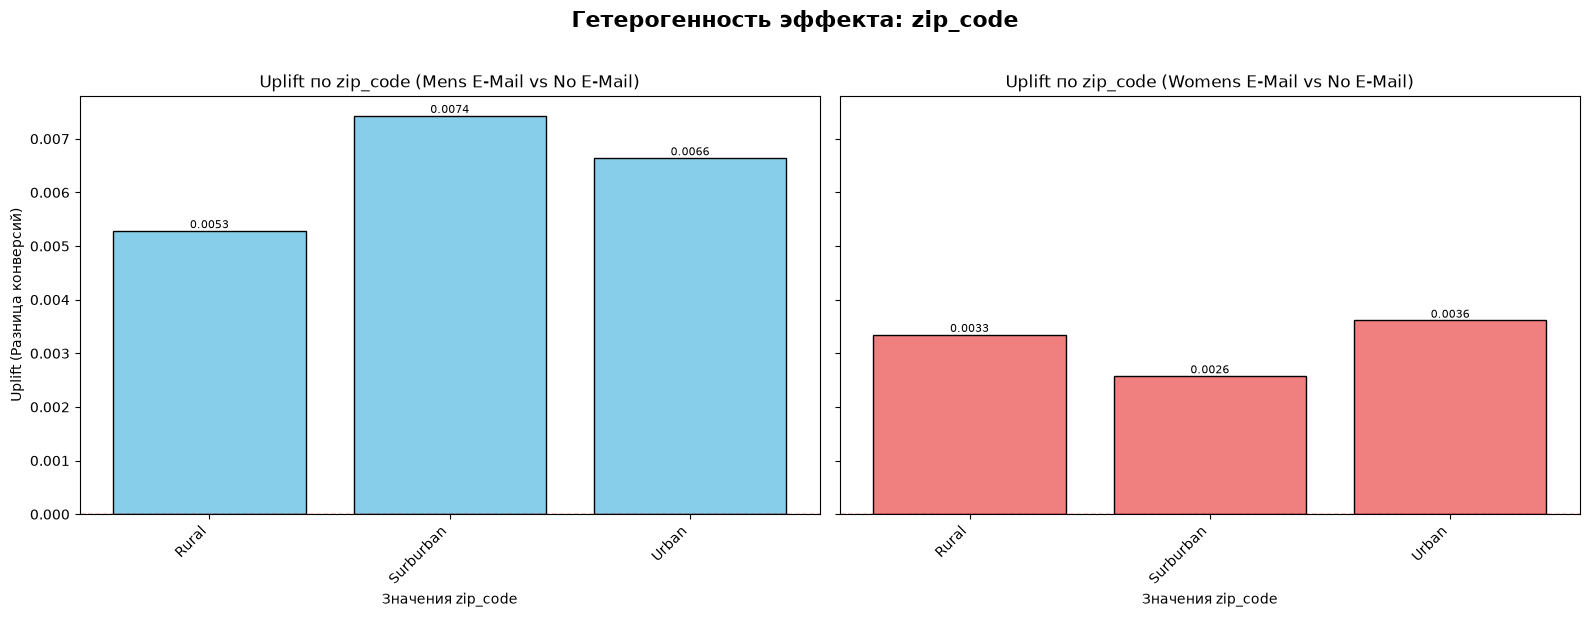

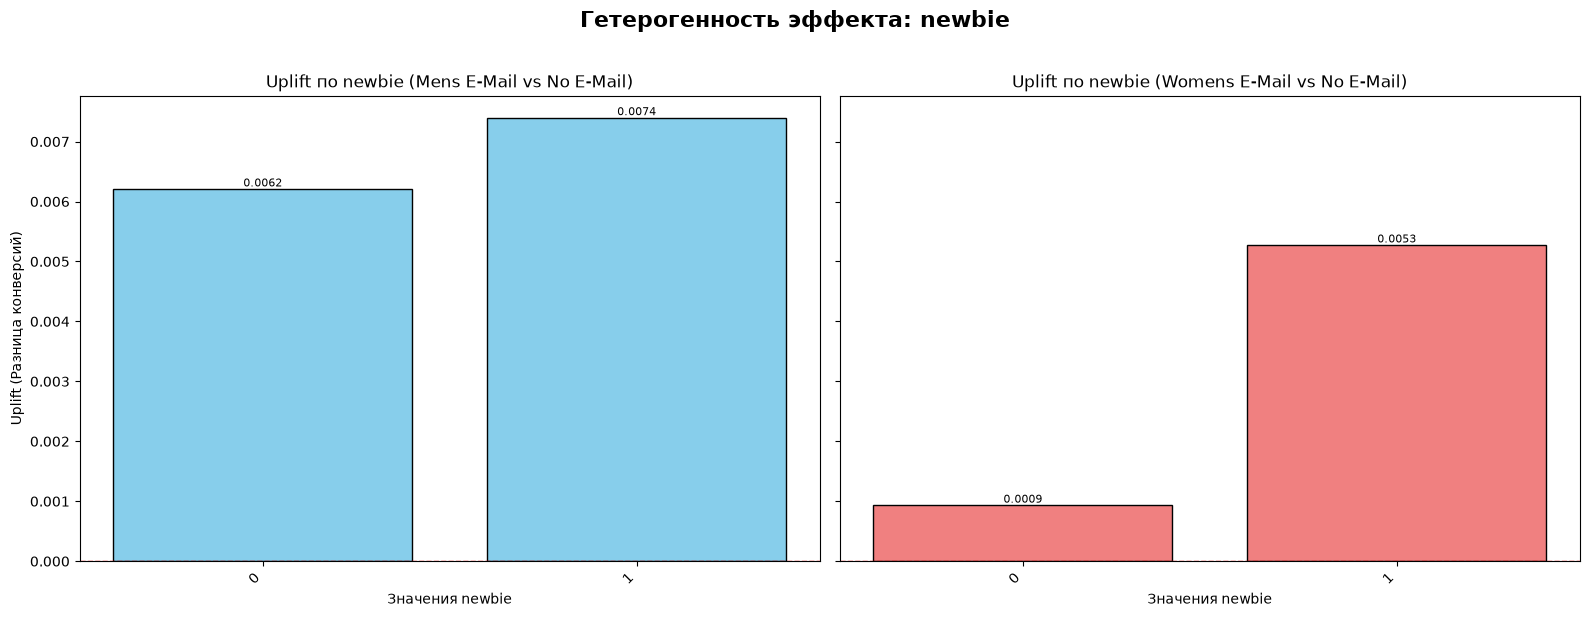

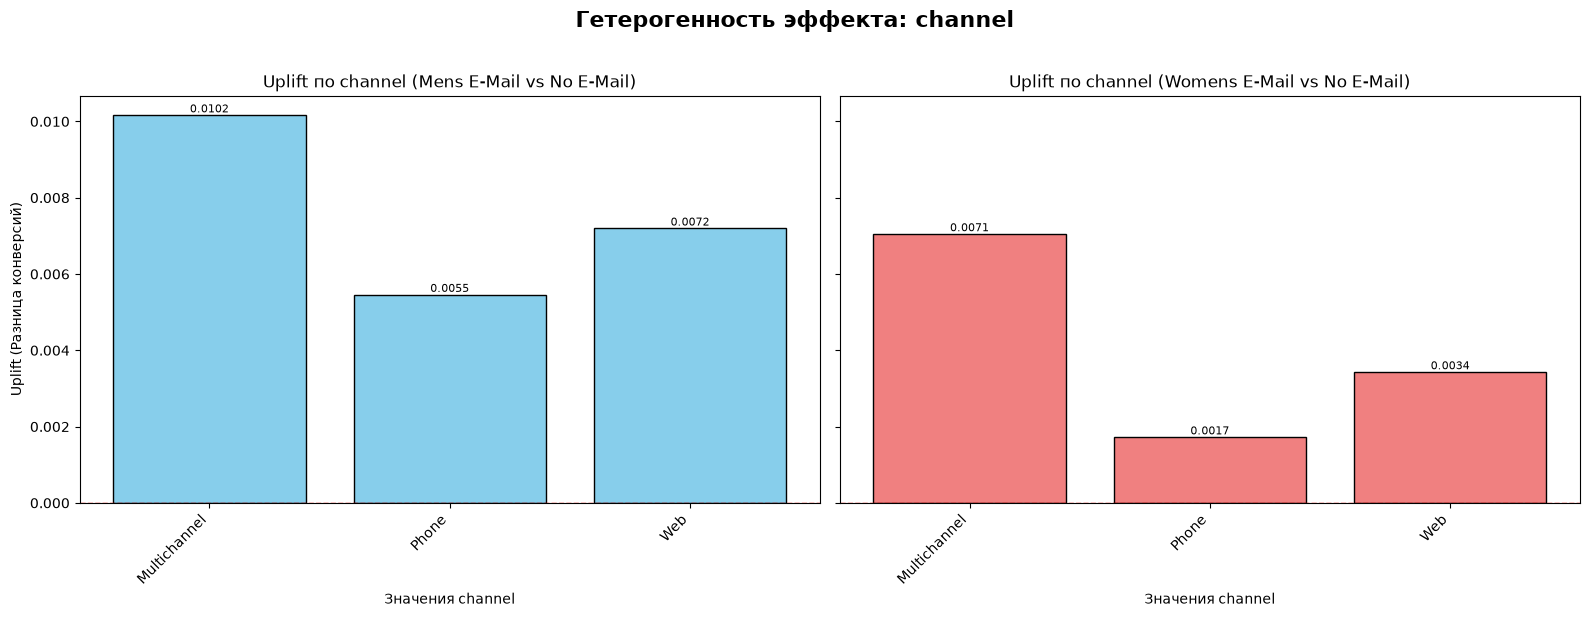

In [ ]:
df_plot = dataset.copy()

features_for_bucket = ['recency', 'history']
features_no_bucket = ['history_segment', 'mens', 'womens', 'zip_code', 'newbie', 'channel']
all_features = features_for_bucket + features_no_bucket

control_name = 'No E-Mail'
test_groups = ['Mens E-Mail', 'Womens E-Mail']

for feature in all_features:
    
    if feature in features_for_bucket:
        col_name = f'bucket_{feature}'
        df_plot[col_name] = pd.qcut(df_plot[feature], q=10, duplicates='drop')
        x_label = f'Бакеты {feature}'
    else:
        col_name = feature
        x_label = f'Значения {feature}'
        
    
    pivot = df_plot.groupby([col_name, 'treatment'], observed=False)['target'].mean().unstack()
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    x_axis = range(len(pivot))
    
    for i, group in enumerate(test_groups):
        ax = axes[i]
        
        uplift = pivot[group] - pivot[control_name]
        
        bars = ax.bar(x_axis, uplift, color='skyblue' if i == 0 else 'lightcoral', edgecolor='black')
        
        ax.axhline(0, color='red', linestyle='--', linewidth=1)
        ax.set_xticks(x_axis)
        ax.set_xticklabels([str(idx) for idx in pivot.index], rotation=45, ha='right')
        ax.set_xlabel(x_label)
        
        if i == 0:
            ax.set_ylabel('Uplift (Разница конверсий)')
            
        ax.set_title(f'Uplift по {feature} ({group} vs {control_name})')
        
        for bar in bars:
            yval = bar.get_height()
            va = 'bottom' if yval >= 0 else 'top'
            ax.text(bar.get_x() + bar.get_width()/2, yval, f'{yval:.4f}', 
                    ha='center', va=va, fontsize=8)
    
    plt.suptitle(f'Гетерогенность эффекта: {feature}', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

**Выводы по анализу**
1) Тест проведен корректно. По графикам и оценкам эффектов видно, что разницы по признакам на историческх данных нет. Значения SMD < 0.1, что указывает на хороший баланс между группами.
2) Эффект от коммуникаций есть. Получаем стат значимой прирост в конверсию как для коммуникаций с женскими товарами, так и с мужскими. При чем от мужский коммуникаций эффект значительно выше
3) Сильных линейных взаимосвязей с таргетом нет. Поэтому в моделях T-learner, S-learner и т.п. лучше использовать нелинейные модели (бустинги, случайные деревья). Также можно удалить категориальный признак history_segment, так как он зависит от признака history
4) При расчете uplift по признакам можно увидеть, что люди с более давними последними попупками (recency) более склонны к покупке после воздействия. Для мужских коммуникаций на всех бинах uplift положительный, для женских есть отрицательный (коммуникации негативно влияют на этот сегмент). Также можно заметить, что рассылка с женскими товарами сильнее влияет на тех людей, кто имел покупки этих товаров в прошлом (для мужских товаров это тоже свойственно, но uplift слабее), а также на новичков.
5) Фичи по разному влияют на покупку в зависимости от воздействия, поэтому в качестве бейзлайна я бы оставил все, кроме history_segment